## CMF-BO-GP 2.0

### Function 2 - Mystery ML Model
Imagine a black box, or a mystery ML model, that takes two numbers as input and returns a log-likelihood score. Your goal is to maximise that score, but each output is noisy, and depending on where you start, you might get stuck in a local optimum. To tackle this, you use Bayesian optimisation, which selects the next inputs based on what it has learned so far. It balances exploration with exploitation, making it well suited to noisy outputs and complex functions with many local peaks.


### Components to the model
#### 1. Import libraries
#### 2. Import and Analyse data - combining baseline data with new queries; then performing statistical analysis on the combined data
#### 3. Visualising data - create a 2D view with showing baseline, additional queries and current maxima - and a 3D representation.
#### 4. Core Model - v1 - UCB / EI models - with length scales and bounds
#### 4.2 Pytorch Experiment - simple pytorch model for comparison
#### 5. Expliotation model - for final queries to maximise outputs (from scipy.optimize import minimize)

In [ ]:
# ==============================================
# 1. Import required libraries to support model
# ==============================================

import numpy as np
import pandas as pd
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from IPython.display import clear_output
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from scipy.stats import norm
from scipy.interpolate import griddata

In [ ]:
# ====================================
# 2. Import and Analyse the data set  
# ====================================

# 1. Load 8D spatial coordinate data and output values
inputs = np.load('/home/mcevoyj777/_CAPSTONE/Models/FUNC2/initial_inputs.npy')
output = np.load('/home/mcevoyj777/_CAPSTONE/Models/FUNC2/initial_outputs.npy')

print(f"Base Maximia: ",output.max())

extra_inputs = [[0.665657, 0.285859],[0.000001, 0.999999],[0.000000, 0.400000],
                [0.873475, 1.000000],[0.804203, 0.167947],[0.700531, 0.998469],
                [0.735062, 0.932771],[0.702637, 0.926564],[0.686448, 0.869564],
               [0.693972, 0.892130], [0.706967, 0.770813],[0.663033, 0.915860]]
extra_output = [0.3700855557672495,-0.04250067518679212,-0.04577773915272362,
                -0.0016845126456047164,0.14065256824649874,0.5200799191934261,
                0.36682621269052196,0.6168419402238136,0.6204482195028495,
               0.698974655198192,0.5433295082777855, 0.4819244388931254]

inputs = np.vstack([inputs, extra_inputs])
output = np.append(output, extra_output)

print(f"Current Maxima: ",output.max())


# Combine into a single Pandas DataFrame
df = pd.DataFrame(inputs, columns=['Input_Y', 'Input_Z'])
df['Output_Target'] = output

# Compute the correlation matrix
# Change method to 'spearman' if relationships are non-linear curves
corr_matrix = df.corr(method='pearson')

# Isolate how each input correlates *only* with the target output
target_corr = corr_matrix['Output_Target'].drop('Output_Target')

print("Correlation with Output:")
print(target_corr)

# Calculate non-linear relationship dependency (higher score = stronger relationship)
mi_scores = mutual_info_regression(inputs, output)

for name, score in zip(['Input_Y', 'Input_Z'], mi_scores):
    print(f"{name} Mutual Information Score: {score:.4f}")


# Fit a quick non-linear model that checks all 2 dimensions simultaneously
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(inputs, output)

# Extract total feature importances (including interactions)
importances = model.feature_importances_

for name, score in zip(['Input_Y','Input_Z'], importances):
    print(f"{name} Total Importance (with interactions): {score:.4f}")

Base Maximia:  0.6112052157614438
Current Maxima:  0.698974655198192
Correlation with Output:
Input_Y    0.623518
Input_Z    0.395776
Name: Output_Target, dtype: float64
Input_Y Mutual Information Score: 0.4247
Input_Z Mutual Information Score: 0.0279
Input_Y Total Importance (with interactions): 0.7901
Input_Z Total Importance (with interactions): 0.2099


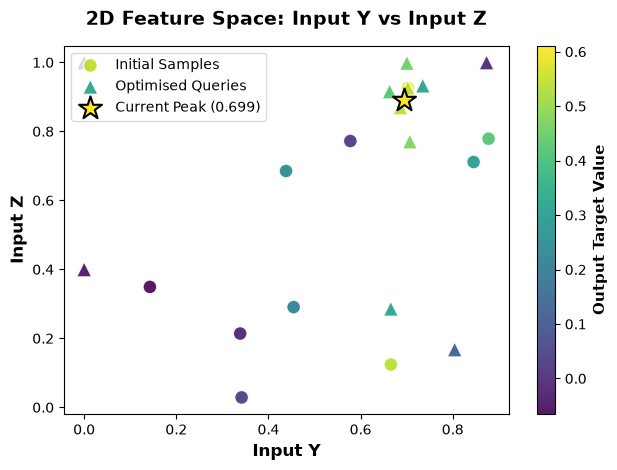

In [3]:
# ===================================
# 3.1 Visualise the data set Y and Z
# ===================================

# Find the coordinates of the maximum value dynamically
max_row_index = df['Output_Target'].idxmax()
max_y = df.loc[max_row_index, 'Input_Y']
max_z = df.loc[max_row_index, 'Input_Z']
max_val = df.loc[max_row_index, 'Output_Target']



# Create scatter plot with the first 10 smaples
scatter1 = plt.scatter(
    data=df.iloc[:10], 
    x='Input_Y', 
    y='Input_Z', 
    c='Output_Target', 
    cmap='viridis', 
    s=100,            # Marker size
    edgecolor='w',    # White border around markers
    alpha=0.9
)

# Plot the next query samples (e.g., as triangles '^')
scatter2 = plt.scatter(
    data=df.iloc[10:len(output)], 
    x='Input_Y', 
    y='Input_Z', 
    c='Output_Target', 
    cmap='viridis', 
    s=120,            # Made slightly larger so triangles stand out nicely
    edgecolor='w',    
    alpha=0.9,
    marker='^',       # <--- Shape for the next points
    vmin=df['Output_Target'].min(),
    vmax=df['Output_Target'].max()
)

scatter3 = plt.scatter(
    x=max_y, 
    y=max_z, 
    c=[max_val],   
    cmap='viridis',    # Highly visible contrasting color
    vmin=df['Output_Target'].min(),
    vmax=df['Output_Target'].max(),
    s=300,            # Much larger marker size to make it pop
    marker='*',       # Star shape
    edgecolor='black',
    linewidth=1.5,
    label=f'Current Max ({max_val:.2f})',
    zorder=5          # Ensures it sits on top of all other points
)


# Add elements
cbar = plt.colorbar(scatter1)
cbar.set_label('Output Target Value', fontsize=11, fontweight='bold')
plt.xlabel('Input Y', fontsize=12, fontweight='bold')
plt.ylabel('Input Z', fontsize=12, fontweight='bold')
plt.title('2D Feature Space: Input Y vs Input Z', fontsize=14, fontweight='bold', pad=15)

plt.legend(
    handles=[scatter1, scatter2,scatter3], 
    labels=['Initial Samples', 'Optimised Queries', f'Current Peak ({max_val:.3f})'],
    loc='upper left', 
    frameon=True, 
    facecolor='white', 
    edgecolor='lightgray', 
    fontsize=10
)
plt.tight_layout()
plt.show()

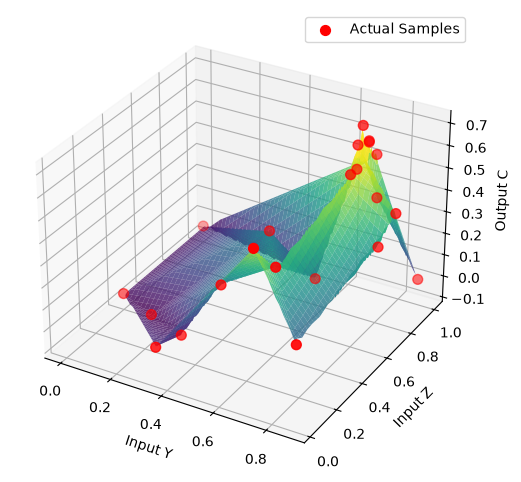

In [4]:
# ===================================
# 3.2 Visualise the data set 3D
# ===================================

# 1. Your 10 matching sample vectors
a = inputs[:, 0]
b = inputs[:, 1]
c = output

# 2. Generate a dense grid boundary over your data range
a_dense = np.linspace(a.min(), a.max(), 100)
b_dense = np.linspace(b.min(), b.max(), 100)
A, B = np.meshgrid(a_dense, b_dense)

# 3. Estimate missing grid data (linear or cubic interpolation)
# Points outside the boundary polygon of your 10 points will return NaN
C = griddata((a, b), c, (A, B), method='linear')

# 4. Render the predicted surface
fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection='3d')
surf = ax.plot_surface(A, B, C, cmap='viridis', edgecolor='none', alpha=0.8)

# 5. Optional: Overlay your original 10 points to verify accuracy
ax.scatter(a, b, c, color='red', s=50, label='Actual Samples')

ax.set_xlabel('Input Y')
ax.set_ylabel('Input Z')
ax.set_zlabel('Output C')
plt.legend()
plt.show()

In [4]:
# ===========================================
# 4 GP Model - with UCB/EI 
# ===========================================

import numpy as np
from sklearn.ensemble import RandomForestRegressor

# Train a predictive model on your existing samples
predictor = RandomForestRegressor(n_estimators=100, random_state=42)
predictor.fit(inputs, output)

def objective_2D(X):
    """
    Surrogate function for 4D optimization.
    X: A 2D numpy array of shape (n_samples, 4) sent by the optimizer.
    """
    # Force input to be 2D array matrix for sklearn compatibility
    X = np.atleast_2d(X)
    
    # Predict the output value using the trained model
    predictions = predictor.predict(X)
    
    # Return as a flat 1D array as expected by your code (.ravel())
    print(predictions)
    return predictions.ravel()

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern
from scipy.stats import norm
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

def upper_confidence_bound(mu, sigma, kappa=0.1):
    """
    Upper Confidence Bound (UCB) acquisition function.
    
    UCB = mean + kappa * std
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation
    kappa : exploration parameter (higher = more exploration)
    """
    return mu + kappa * sigma

def expected_improvement(mu, sigma, y_best, xi=0.01):
    """
    Expected Improvement (EI) acquisition function.
    
    EI = E[max(f(x) - f(x_best), 0)]
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation  
    y_best : best observed value so far
    xi : exploration parameter
    """
    with np.errstate(divide='warn'):
        improvement = mu - y_best - xi
        Z = improvement / sigma
        ei = improvement * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei

In [6]:
def bayesian_optimization_nd(objective_func, n_dims, n_iterations=1, 
                            n_initial=10, acquisition='ei'):
    """
    Bayesian Optimization for n-dimensional functions.
    Assumes bounds [0, 1] for all dimensions.
    """
    bounds = [(0, 1) for _ in range(n_dims)]
    
    # Initialize
    X_samples = inputs
    y_samples = output
    
    
    best_values = [y_samples.max()]
    
    print(f"Starting {n_dims}D optimization with {n_initial} initial samples...")
    print(f"Initial best: {y_samples.max():.4f}\n")
  
    
    for iteration in range(n_iterations):
        # Fit GP
        kernel = ConstantKernel(1.0) * Matern(length_scale=0.1,nu=2.5)
        gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-3,normalize_y=True,
                                     n_restarts_optimizer=5)
        gp.fit(X_samples, y_samples)

        # Optimize acquisition function
        def acq_objective(X):
            X = X.reshape(1, -1)
            mu, sigma = gp.predict(X, return_std=True)
            
            if acquisition == 'ei':
                acq_val = expected_improvement(mu, sigma, y_samples.max())
            else:
                acq_val = upper_confidence_bound(mu, sigma, kappa=1)
           
            return -acq_val
        
        # Multi-start optimization
        best_acq = np.inf
        X_next = None
        
        for _ in range(30):  # More starts for higher dimensions
            x0 = np.random.uniform(0, 1, n_dims)
            result = minimize(acq_objective, x0, bounds=bounds, method='L-BFGS-B')
            if result.fun < best_acq:
                best_acq = result.fun
                X_next = result.x
                print(f"Optimized Next Point Found! Predicted Acquisition Score: {-best_acq:.6f}")
                print(f"Coordinates to test next: {X_next}")

       
        # Evaluate
        y_next = objective_func(X_next.reshape(1, -1)).ravel()
        
        # Update
        X_samples = np.vstack([X_samples, X_next])
        y_samples = np.append(y_samples, y_next)
        best_values.append(y_samples.max())
        
        if (iteration + 1) % 10 == 0:
            print(f"Iteration {iteration + 1}: Best f(x)={y_samples.max():.4f}")
    
    return X_samples, y_samples, best_values



# Run 6D optimization
X_samples_2d, y_samples_2d, best_values_2d = bayesian_optimization_nd(
    objective_2D, 
    n_dims=2,
    n_iterations=3,
    acquisition='ei'
)

Starting 2D optimization with 10 initial samples...
Initial best: 0.6990

Optimized Next Point Found! Predicted Acquisition Score: 0.015311
Coordinates to test next: [0.73095477 0.83849817]
Optimized Next Point Found! Predicted Acquisition Score: 0.016637
Coordinates to test next: [0.71832246 0.87241197]
Optimized Next Point Found! Predicted Acquisition Score: 0.016637
Coordinates to test next: [0.71832212 0.87241252]
[0.60116931]
Optimized Next Point Found! Predicted Acquisition Score: 0.005131
Coordinates to test next: [0.68434203 0.41920116]
Optimized Next Point Found! Predicted Acquisition Score: 0.005614
Coordinates to test next: [0.98061561 0.78492217]
Optimized Next Point Found! Predicted Acquisition Score: 0.008855
Coordinates to test next: [0.76385464 0.79237225]
[0.39408708]
Optimized Next Point Found! Predicted Acquisition Score: 0.004898
Coordinates to test next: [0. 0.]
Optimized Next Point Found! Predicted Acquisition Score: 0.005579
Coordinates to test next: [0.9803427 0

In [9]:
# ===========================================
# 4.2 Pytorch Model (experiment)
# ===========================================

import torch
from botorch.models import SingleTaskGP
from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import ExactMarginalLogLikelihood
from botorch.acquisition import qLogExpectedImprovement
from botorch.optim import optimize_acqf


# 2. Optimization Settings
DIM = 2
N_INIT = 5          # Number of initial random evaluations
N_ITERATIONS = 5    # Number of Bayesian Optimization rounds
BATCH_SIZE = 1      # Evaluate 1 point at a time

# Bounds for tensor
bounds = torch.tensor([[0.0, 0.0], [1.0, 1.0]], dtype=torch.double)

# 3. Generate initial training data
train_X = torch.tensor(inputs, dtype=torch.double)      # Shape: (N, 2)
train_Y = torch.tensor(output, dtype=torch.double).unsqueeze(-1)  # Shape: (N, 1)

print(f"Initial best observed value: {train_Y.max().item():.4f}")

# 4. Main Bayesian Optimization Loop
for i in range(N_ITERATIONS):
    # Standardize outputs to help the GP fit better
    standardized_Y = (train_Y - train_Y.mean()) / train_Y.std()
    
    # Fit the Gaussian Process model
    # SingleTaskGP automatically infers and adds a Gaussian noise kernel (Homoskedastic)
    gp = SingleTaskGP(train_X, standardized_Y)
    mll = ExactMarginalLogLikelihood(gp.likelihood, gp)
    fit_gpytorch_mll(mll)
    
    # Define Expected Improvement acquisition function
    # xi=0.1 adds a jitter parameter to heavily encourage exploration over exploitation
    acq_func = qLogExpectedImprovement(
        model=gp,
        best_f=standardized_Y.max()
       
    )
    
    # Optimize the acquisition function to find the next best inputs
    new_X, acq_value = optimize_acqf(
        acq_function=acq_func,
        bounds=bounds,
        q=BATCH_SIZE,
        num_restarts=10,
        raw_samples=25,
    )


    print(f"Iteration {i+1}/{N_ITERATIONS} | Best Value: {train_Y.max().item():.4f} | Next Point: {new_X.numpy()[0]}")

# 5. Final Results
best_idx = train_Y.argmax()
print("\n--- Optimization Complete ---")
print(f"Best Input Coordinates: {train_X[best_idx].numpy()}")
print(f"Best Noisy Log-Likelihood Score: {train_Y[best_idx].item():.4f}")

Initial best observed value: 0.6990
Iteration 1/5 | Best Value: 0.6990 | Next Point: [0.62130598 0.07626074]
Iteration 2/5 | Best Value: 0.6990 | Next Point: [0.62132789 0.07626139]
Iteration 3/5 | Best Value: 0.6990 | Next Point: [0.62136466 0.0762623 ]
Iteration 4/5 | Best Value: 0.6990 | Next Point: [0.91112804 0.60652543]
Iteration 5/5 | Best Value: 0.6990 | Next Point: [0.62094682 0.07625144]

--- Optimization Complete ---
Best Input Coordinates: [0.693972 0.89213 ]
Best Noisy Log-Likelihood Score: 0.6990


In [10]:
# ============================================
# 5. Exploitation Model - scipy.optimize
# ============================================

## import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C
from scipy.optimize import minimize

# 1. Load the 3D dataset (Features: Y, Z)
X_train = inputs
y_train = output

# 2. Configure a Matern GP Surrogate Model
# Matern nu=1.5 allows for the distinct "cliffs"
kernel = C(1.0, (1e-3, 1e3)) * Matern(length_scale=np.ones(2), length_scale_bounds=(1e-2, 10.0), nu=1.5)
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=25, alpha=1e-6, random_state=42)

# Fit model to historical space
gp.fit(X_train, y_train)

# 3. Formulate Optimization Target (Negative prediction for minimization algorithm)
def objective(x):
    # Predict returns shape (1, 2), flatten to extract scalar
    return -float(gp.predict(x.reshape(1, -1))[0])

# 4. Enforce Bounding Box System limits [0.0, 1.0]
bounds = [
    (0.60, 1.0),  # Y
    (0.60, 1.0)   # Z
]

# Use your historical peak coordinate as the optimization warm-start point
x_start = np.array([ 0.693972, 0.892130])

# 5. Execute L-BFGS-B Optimization Local Search
result = minimize(objective, x_start, method='L-BFGS-B', bounds=bounds)

# 6. Display Predicted Coordinates
print("--- GAUSSIAN PROCESS TARGET PREDICTION ---")
print(f"Predicted Max Output: {abs(result.fun):.4f}")
print("Optimal Coordinates:")
for name, val in zip(['Y', 'Z'], result.x):
    print(f"  Input_{name}: {val:.6f}")



--- GAUSSIAN PROCESS TARGET PREDICTION ---
Predicted Max Output: 0.6998
Optimal Coordinates:
  Input_Y: 0.694857
  Input_Z: 0.890721
